# Chapter 3: Polynomial Regression

In [5]:
%reset
low_memory=False
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

## 3.1 Introduction & Motivation

In the previous chapter, we saw how we could use the linear function to accurately draw a line through a cloud of points, and how this might give us predictive value in some situations. In this chapter, we move a little bit further. We're still looking for a function that approximates the relationship we find among variables, but we're no longer working with linear functions. In this case, we're working with *polynomial functions*. This results into **polynomial regression** as a method.

## 3.2 Problem Setting

In the previous chapter, we already discussed how the Linear Regression model, though strong, has its limitations. Most importantly, the linear regression model van only model linear relations between variables. It should be noted that this is extremely limiting, and that there are a bunch of relationship variables who might not be linear. (For what exactly a linear relationship is, refer back to the 4 points we defined in chapter 1.)

#### Question 1: Can you think of relationships of variables which are definitely not linear? Give 3 examples, and explain why this is the case.

- Leeftijd vs inkomen → stijgt eerst, stabiliseert later

- Temperatuur vs ijsverkoop → stijgt sneller bij hogere temperaturen

- Snelheid vs remweg → kwadratisch verband

- Tijd vs populatiegroei → exponentieel

- Tijd vs sin-golf (zoals in de dataset)

Deze relaties kunnen niet goed beschreven worden met een rechte lijn.

To give an example of how such data would look, let's generate a dataset which is definitely not linear:

In [6]:
x = np.linspace(0, 3, 100) 
rng = np.random.RandomState(42)
y = np.sin(4 * x) + x + rng.uniform(size=len(x))
X = x[:, np.newaxis]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

Let's make a scatterplot to illustrate the non-linearity of this dataset:

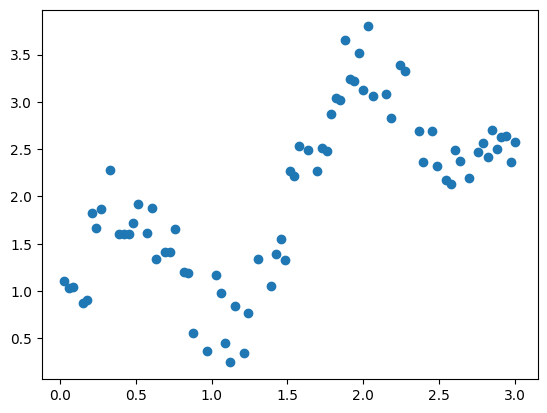

In [7]:
plt.scatter(X_train, y_train)
plt.show()

#### Question 2: Why is this dataset not linear? Elaborate.

De dataset is niet lineair omdat:

- De relatie volgt een sinusvorm:
    `y = sin(4x) + x + noise`

- De punten vormen een golvende curve

- Een rechte lijn kan deze vorm niet goed volgen

Een lineair model kan alleen rechte lijnen maken, geen krommen.

#### Question 3: Try to fit a linear regression model on this data. Also calculate the evaluation metrics. Does this model make any sense whatsoever? How would you describe the issue?

In [8]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)

y_pred = regressor.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

MAE: 0.7203963843057821
MSE: 0.7043403658672862


In [9]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [10]:
print('The R2 score of the model on the test set is:', regressor.score(X, y))
y_pred = regressor.predict(X).reshape(-1, 1)
print('The MAE of the model on the test set is:', mean_absolute_error(y_pred, y))
print('The MSE of the model on the test set is:', mean_squared_error(y_pred, y))

The R2 score of the model on the test set is: 0.41647612632814246
The MAE of the model on the test set is: 0.5871618477220024
The MSE of the model on the test set is: 0.5047688098345076


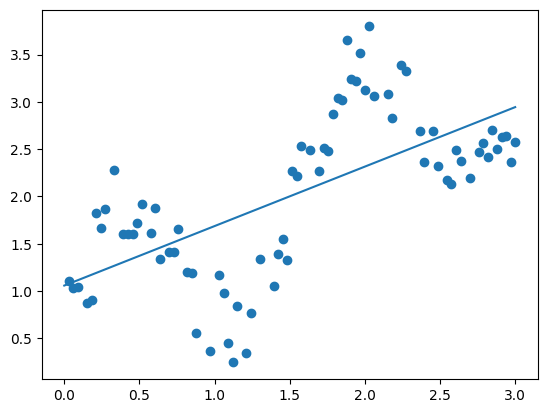

In [11]:
plt.scatter(X_train, y_train)

min_pt = X.min() * regressor.coef_[0] + regressor.intercept_
max_pt = X.max() * regressor.coef_[0] + regressor.intercept_

plt.plot([X.min(), X.max()], [min_pt, max_pt])

plt.show()

## 3.3 Model

### 3.3.1 Model

The model we'll use to fit this type of data is called the **Polynomial Regression Model** and is in essence a generalization of the Linear Regression Model. Where the linear regression model is based upon a linear function, the Polynomial Regression Model is based upon a much broader class of functions in order to include much more complicated function patterns: 

$$y = \beta_0 + \beta_1 x^1 + \beta_2 x^2 + \beta_3 x^3 + ...$$ 

You do not need to know the function formula, you should just understand the following things:

* Polynomial Regression works with a much broader class of functions than Linear Regression
* This allows us to also model non-linear patters
* Polynomial Regression requires a "hyperparameter"

The hyperparameter we refer to, is a number from 0, 1, 2, ... up to as much you wish (though only seldom values above 7 are encountered). This value determines the form of a function. It says how many arches can be found in the function. This number is something we have to give to the model before fitting it.

The fitting algorithms then once again takes care of the rest.

### 3.3.2 Model Estimation

As said in the previous section, when we want to fit a Polynomial Regression Model, we first have to give the model a certain value for the hyperparameter. Let's start with 0 and see what happens:

In [12]:
model = LinearRegression()
pol_0 = PolynomialFeatures(degree=0)
model.fit(pol_0.fit_transform(X_train), y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


As you can see in the code, we've started off from a linear regression model and then "added" a polynomial part to it. The interested reader might compare the polynomial function with the linear function and remark why this is.

Let's draw the function we have fitted:

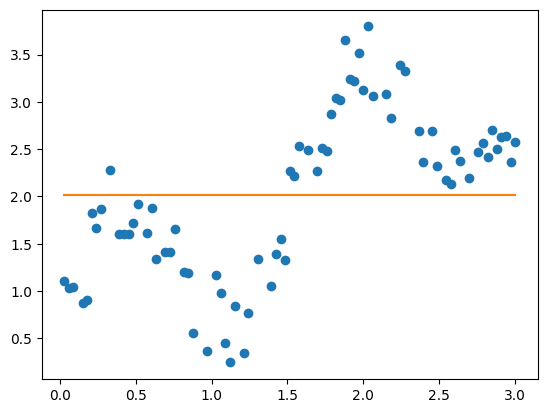

In [13]:
x = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1,1) 
plt.plot(X_train, y_train, 'o')
plt.plot(x, model.predict(pol_0.fit_transform(x))) 
plt.show()

That's odd!! When our hyperparameter is equal to 0, our function is even worse than the linear regression function... 
Let's try and see what's going on, shall we?

#### Question 4: The code below provides a function combining all the steps in making a polynomial regression (creating the model, fitting the model, and plotting the model) while asking an input for the hyperparameter. Try and figure out which hyperparameter gives the best model. Why is this so? 

The R2 score of this model on the train set is: 0.415082394545103


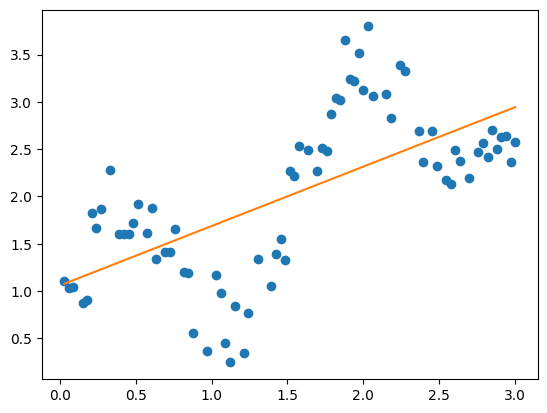

The R2 score of this model on the train set is: 0.41738261536263765


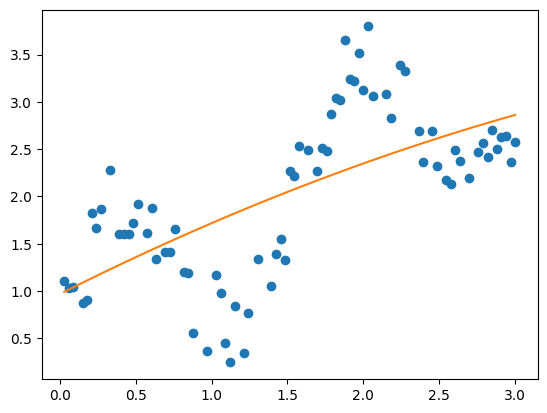

The R2 score of this model on the train set is: 0.5823333503092083


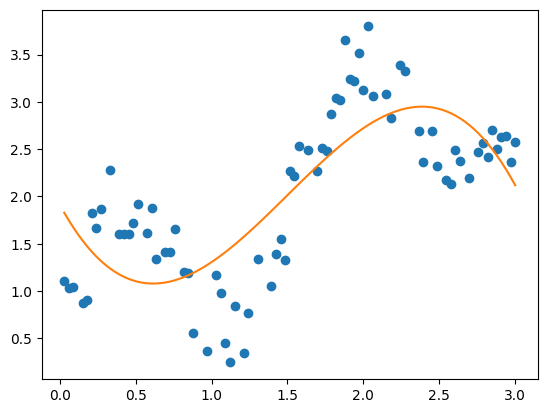

The R2 score of this model on the train set is: 0.5951307149293492


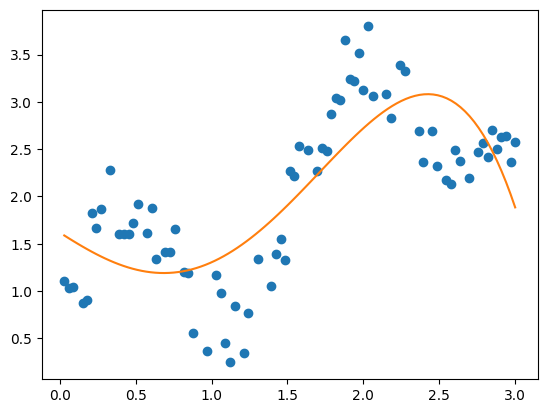

The R2 score of this model on the train set is: 0.8555374678146485


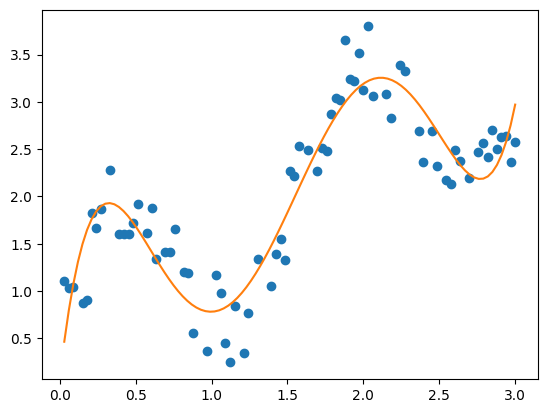

The R2 score of this model on the train set is: 0.8563805544483711


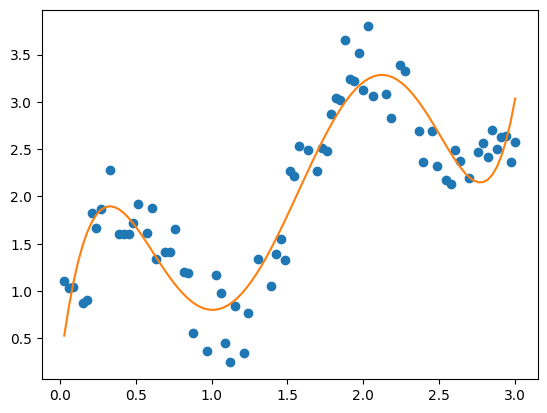

The R2 score of this model on the train set is: 0.9127806464712661


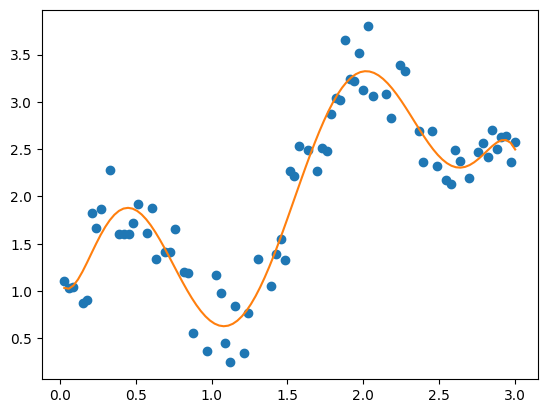

The R2 score of this model on the train set is: 0.9131223255373249


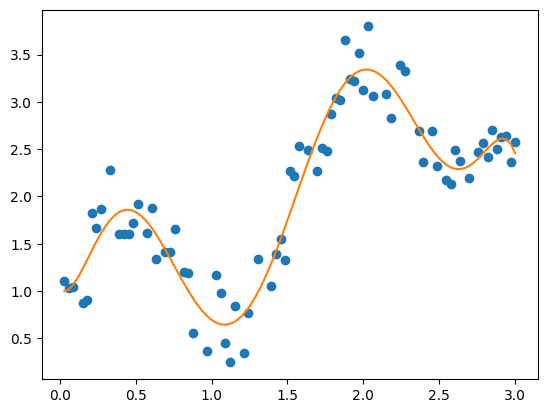

In [14]:
def poly_test(x):
    pol_exp = PolynomialFeatures(degree=x)
    model = LinearRegression()
    model.fit(pol_exp.fit_transform(X_train), y_train)
    print('The R2 score of this model on the train set is:', model.score(pol_exp.fit_transform(X_train), y_train))
    x = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1,1) 
    plt.plot(X_train, y_train, 'o')
    plt.plot(x, model.predict(pol_exp.fit_transform(x))) 
    plt.show()


poly_test(1)
poly_test(2)
poly_test(3)
poly_test(4)
poly_test(5)
poly_test(6)
poly_test(7)
poly_test(8)

De degree zorgt voor het volgende:
- Volgt de curve goed
- Niet te complex
- Beste balans

## 3.4 Model Evaluation

The evaluation criteria we have used for the linear regression model are still valid for polynomial regression. Make the following exercise to see if you can get some information from it:

#### Question 5: Calculate both evaluation criteria we have seen for all the models you have tried in question 4. Does it confirm your suspicions?

In [15]:
for deg in range(0, 11):

    pol = PolynomialFeatures(degree=deg)
    model = LinearRegression()

    X_train_poly = pol.fit_transform(X_train)
    X_test_poly  = pol.transform(X_test)

    model.fit(X_train_poly, y_train)
    y_pred = model.predict(X_test_poly)

    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    ss_res = np.sum((y_test - y_pred) ** 2)
    ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    print("Degree:", deg)
    print("R2:", r2)
    print("MAE:", mae)
    print("MSE:", mse)
    print()

Degree: 0
R2: -0.01924932442115046
MAE: 0.9712684934225696
MSE: 1.218166502084737

Degree: 1
R2: 0.41067297381418255
MAE: 0.7203963843057821
MSE: 0.7043403658672862

Degree: 2
R2: 0.41069905704961895
MAE: 0.7183502207943914
MSE: 0.704309192215351

Degree: 3
R2: 0.528018230196996
MAE: 0.63748720974929
MSE: 0.5640939540433

Degree: 4
R2: 0.573585159523538
MAE: 0.6175923410600813
MSE: 0.5096341613522622

Degree: 5
R2: 0.8463569260655447
MAE: 0.3819086335703193
MSE: 0.18362812852544697

Degree: 6
R2: 0.8525232800134497
MAE: 0.3712486461489258
MSE: 0.17625834604008517

Degree: 7
R2: 0.8670815754380284
MAE: 0.35846843886929575
MSE: 0.1588588468314426

Degree: 8
R2: 0.8714577650497397
MAE: 0.3558868893999738
MSE: 0.15362859799631542

Degree: 9
R2: 0.870389727819639
MAE: 0.35623611713796577
MSE: 0.15490507387470462

Degree: 10
R2: 0.8661393863304832
MAE: 0.35926851826670286
MSE: 0.15998491400847267



Beste performence:
- Degree 7-8
- Hoogste R²
- Laagste MAE
- Laagste MSE

## 3.5 Exercises

#### Question 1: See section 3.2

#### Question 2: See section 3.2

#### Question 3: See section 3.2

#### Question 4: See section 3.3.2

#### Question 5: See section 3.4

#### Question 6: In section 3.3.2 we created a function where wou could pass the factor of our function as a value called x. Finding the best value for x is an important task to get the best model possible. Taking into account what we learned last week, how would you find the ideal value for x to prevent overfitting?

In [16]:
def poly_test(x):

    pol_exp = PolynomialFeatures(degree=x)
    model = LinearRegression()

    # transform data for polynomial
    X_train_poly = pol_exp.fit_transform(X_train)
    X_test_poly = pol_exp.transform(X_test)

    # train model
    model.fit(X_train_poly, y_train)

    # predictions
    y_train_pred = model.predict(X_train_poly)
    y_test_pred = model.predict(X_test_poly)

    # R2 scores
    print("Degree:", x)
    print("Train R2 score:", model.score(X_train_poly, y_train))
    print("Test R2 score:", model.score(X_test_poly, y_test))

    # MSE scores
    print("Train MSE:", mean_squared_error(y_train, y_train_pred))
    print("Test MSE:", mean_squared_error(y_test, y_test_pred))

    print()

poly_test(1)
poly_test(2)
poly_test(10)
poly_test(100)

Degree: 1
Train R2 score: 0.415082394545103
Test R2 score: 0.41067297381418255
Train MSE: 0.43824495782358125
Test MSE: 0.7043403658672862

Degree: 2
Train R2 score: 0.41738261536263765
Test R2 score: 0.41069905704961895
Train MSE: 0.43652153530088006
Test MSE: 0.704309192215351

Degree: 10
Train R2 score: 0.9133615109854862
Test R2 score: 0.8661393863304832
Train MSE: 0.06491321274991468
Test MSE: 0.15998491400847267

Degree: 100
Train R2 score: 0.054036504107056516
Test R2 score: -0.005923146357776465
Train MSE: 0.7087557777267443
Test MSE: 1.202239580841166

